# Multi-Key OpenWInD Whistle Design Pipeline

Dieses Notebook orchestriert die drei Stufen Bore/Oktave, Tonlochplatzierung und Undercutting für mehrere Whistle-Tonarten. Die schwere Modell- und Optimierungslogik liegt im Package `tin_whistle_openwind`.

In [1]:
from pathlib import Path
import importlib
import json
import numpy as np
import matplotlib.pyplot as plt

import tin_whistle_openwind.optimizer as optimizer_module
import tin_whistle_openwind.optimize_toneholes as tonehole_module
import tin_whistle_openwind.pipeline as pipeline_module
importlib.reload(optimizer_module)
importlib.reload(tonehole_module)
importlib.reload(pipeline_module)

from tin_whistle_openwind.keys import SUPPORTED_KEYS
from tin_whistle_openwind.tuning import (
    IRISH_FOLK_HYBRID, EQUAL_TEMPERAMENT, JUST_INTONATION,
    STANDARD_FINGERINGS, generate_key_frequencies,
)
from tin_whistle_openwind.pipeline import WhistleDesignPipeline
from tin_whistle_openwind.optimizer import fingering_chart_rows

TEMPERAMENTS = {
    'Irish_Folk_Hybrid': IRISH_FOLK_HYBRID,
    '12-TET': EQUAL_TEMPERAMENT,
    'Just_Intonation': JUST_INTONATION,
}
KEY_NAME = 'Soprano_D'
PIPE_INNER_DIAMETER_MM = 14.2  # DN16 PVC
TEMPERAMENT_NAME = 'Irish_Folk_Hybrid'
print('Keys:', ', '.join(SUPPORTED_KEYS))

Keys: Soprano_D, Soprano_C, High_Bb, Alto_A, Low_D


## 1. Key- und Temperamentauswahl

Die Tonleiter wird aus der Grundfrequenz und Cent-Intervallen erzeugt. Der Irish Folk Hybrid ist der Default; 12-TET und Just Intonation können über `TEMPERAMENT_NAME` gewählt werden.

In [2]:
key_config = SUPPORTED_KEYS[KEY_NAME]
tuning = TEMPERAMENTS[TEMPERAMENT_NAME]
targets_hz = generate_key_frequencies(key_config, TEMPERAMENT_NAME)
print(key_config.name, '|', tuning.name)
for note, frequency in targets_hz.items():
    print(f'{note:20s} {frequency:8.2f} Hz')

print('D6 fingering:', STANDARD_FINGERINGS['Octave_Degree_1'])
print('Fork fingering:', STANDARD_FINGERINGS['Fork_Minor7'])

Soprano High D | Irish Folk Hybrid (HB-trad / Copeland standard)
Degree_1               587.33 Hz
Degree_2               660.02 Hz
Degree_3               736.58 Hz
Degree_4               783.99 Hz
Degree_5               880.00 Hz
Degree_6               983.21 Hz
Fork_Minor7           1042.88 Hz
Degree_7              1105.53 Hz
Octave_Degree_1       1174.66 Hz
D6 fingering: [0, 1, 1, 1, 1, 1]
Fork fingering: [0, 1, 1, 0, 0, 0]


## 2. Stage 1: Rohrlaenge und Endloch

DN16-PVC mit 14.2 mm Innendurchmesser: Optimiert werden die vorlaeufige Rohrlaenge ohne Tonloecher und der Endradius. Nur die letzten 20 mm verjuengen sich linear; der restliche Bore bleibt konstant. Das kalibrierte Mundstueck bleibt unveraendert. Stage 2 korrigiert die Laenge anschliessend gemeinsam mit den Tonloechern.

Bore: Soprano High D optimized bore | length: 248.7 mm


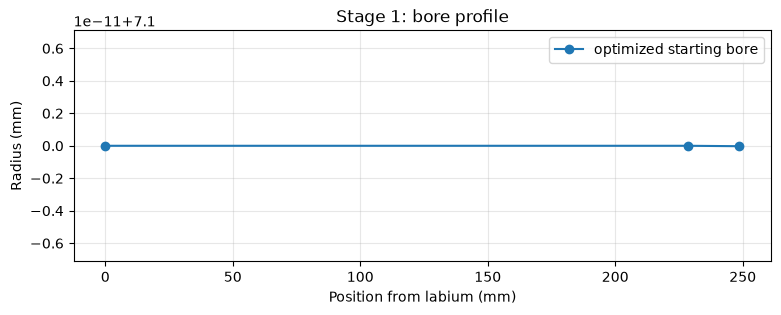

In [3]:
pipeline = WhistleDesignPipeline(KEY_NAME, tuning)
bore = pipeline.run_stage_1_length_endhole_optimization(
    starting_bore_radius_m=PIPE_INNER_DIAMETER_MM / 2000.0,
)
print('Bore:', bore.name, '| length:', f'{bore.length_m * 1000:.1f} mm')

positions_mm = [position * 1000 for position, _ in bore.segments]
radii_mm = [radius * 1000 for _, radius in bore.segments]
plt.figure(figsize=(9, 3))
plt.plot(positions_mm, radii_mm, 'o-', label='optimized starting bore')
plt.xlabel('Position from labium (mm)')
plt.ylabel('Radius (mm)')
plt.title('Stage 1: bore profile')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 3. Stage 2: Tonlochplatzierung und Bohrplan

Die sechs Löcher werden innerhalb jeder Hand mit mindestens 18 mm Abstand, 5-8 mm Durchmesser und mindestens 30 mm Abstand zum Rohrende optimiert. Zwischen L3 und R1 entfaellt der 18-mm-Mindestabstand; nur die axiale Reihenfolge bleibt mit 0.1 mm numerischem Abstand erhalten (kein Bohrkantenabstand). Die Rohrlaenge wird innerhalb von +/-5% mitoptimiert, damit die geschlossenen Tonlochkamine beim Grundton beruecksichtigt werden. Der geschlossene Grundton wird im Optimierungs-Sweep auf maximal 0.1 Cent Abweichung begrenzt, statt gegen andere Toene abgewogen. Bore-Radien und die 20-mm-Endverjuengung bleiben erhalten. Bohrplan, Griffingtabelle und Export verwenden danach diese endgueltige Laenge. Fork-Fingerings und das vented D6 sind Teil der OpenWInD-Fingering-Chart.

In [4]:
holes = pipeline.run_stage_2_tonehole_optimization(bore)
tonehole_result = pipeline.tonehole_result
bore = tonehole_result.bore
print(f'Pipe length after tonehole optimization: {bore.length_m * 1000:.2f} mm')
print(f'Optimizer status: {tonehole_result.result.message}')
print(f'Initial cost: {tonehole_result.initial_cost:.3f}')
print(f'Final cost:   {tonehole_result.final_cost:.3f}')
print(f'Improvement:  {tonehole_result.improvement:.3f} ({tonehole_result.improvement / max(abs(tonehole_result.initial_cost), 1e-12) * 100:.2f}%)')
print(f'Objective improved: {tonehole_result.improved}')
print('Die folgenden Tabellen zeigen den Bohrplan und beide Register separat.')

Pipe length after tonehole optimization: 246.12 mm
Optimizer status: Optimization terminated successfully
Initial cost: 25725.303
Final cost:   367.271
Improvement:  25358.032 (98.57%)
Objective improved: True
Die folgenden Tabellen zeigen den Bohrplan und beide Register separat.


### Bohrplan und Grifftabelle beider Oktaven

Positionen werden ab **Rohranfang**, nicht ab Labium, angegeben. `x` = geschlossen, `o` = offen; Reihenfolge vom Mundstueck zum Rohrende: L1 bis R3. Cent-Werte beziehen sich auf das gewaehlte Temperament; positive Werte sind zu hoch, negative zu tief. Die zweite Oktave wird separat akustisch simuliert, mit ventiliertem Grundtongriff. Es handelt sich um Modellresonanzen, nicht um gemessene Spieltoene. Fehlende Peaks werden als solche angezeigt. Stage 2 optimiert nicht alle Toene der zweiten Oktave; diese Tabelle dient auch ihrer Kontrolle.

In [5]:
import pandas as pd
from IPython.display import display
from tin_whistle_openwind.reporting import drilling_chart_rows, fingering_tuning_rows

rows = drilling_chart_rows(holes, bore.length_m)
drilling_table = pd.DataFrame(rows).rename(columns={
    'Hole name': 'Loch', 'Hole': 'Nr.',
    'Position from pipe start (mm)': 'Position ab Rohranfang (mm)',
    'Spacing (mm)': 'Abstand zum vorigen Loch (mm)',
    'Distance from end (mm)': 'Abstand zum Rohrende (mm)',
    'Drill diameter (mm)': 'Bohrdurchmesser (mm)',
})
display(drilling_table.style.hide(axis='index').set_caption('Bohrplan').format({
    column: '{:.2f}' for column in drilling_table if column.endswith('(mm)')
}, na_rep='-'))

mouthpiece = pipeline.geometry_factory.load_mouthpiece('MouthpieceDN16V2')
fingering_table = pd.DataFrame(fingering_tuning_rows(
    key_config, tuning, bore, holes, mouthpiece,
    temperature=pipeline.geometry_factory.temperature,
)).rename(columns={
    'Register': 'Oktave', 'Degree': 'Stufe', 'Target (Hz)': 'Soll (Hz)',
    'Simulated (Hz)': 'Simulation (Hz)', 'Deviation (cents)': 'Abweichung (Cent)',
})
fingering_table['Stufe'] = fingering_table['Stufe'].replace({
    **{f'Degree_{i}': str(i) for i in range(1, 8)}, 'Fork_Minor7': 'b7 (Gabelgriff)',
})

def cent_color(value):
    if pd.isna(value):
        return 'background-color: #eeeeee; color: #333333'
    color = '#d9ead3' if abs(value) <= 5 else '#fff2cc' if abs(value) <= 15 else '#f4cccc'
    return f'background-color: {color}; color: #222222'

for octave in (1, 2):
    table = fingering_table[fingering_table['Oktave'] == octave].drop(columns='Oktave')
    display(table.style.hide(axis='index').set_caption(
        f'{octave}. Oktave - {tuning.name} (x = geschlossen, o = offen)'
    ).format({
        'Soll (Hz)': '{:.2f}', 'Simulation (Hz)': '{:.2f}', 'Abweichung (Cent)': '{:+.2f}',
    }, na_rep='kein Peak').map(cent_color, subset=['Abweichung (Cent)']))
print('Cent-Farben: bis 5 = gruen, bis 15 = gelb, darueber = rot.')

Loch,Nr.,Position ab Rohranfang (mm),Abstand zum vorigen Loch (mm),Abstand zum Rohrende (mm),Bohrdurchmesser (mm)
L1,1,102.02,-,144.10,7.32
L2,2,120.12,18.10,126.00,7.21
L3,3,138.22,18.10,107.90,6.80
R1,4,159.80,21.58,86.32,5.26
R2,5,177.90,18.10,68.22,8.00
R3,6,203.27,25.36,42.85,8.00


Stufe,L1,L2,L3,R1,R2,R3,Soll (Hz),Simulation (Hz),Abweichung (Cent),Status
1,x,x,x,x,x,x,587.33,587.30,-0.10,OK
2,x,x,x,x,x,o,660.02,660.13,+0.29,OK
3,x,x,x,x,o,o,736.58,736.36,-0.51,OK
4,x,x,x,o,o,o,783.99,783.97,-0.04,OK
5,x,x,o,o,o,o,880.00,879.89,-0.22,OK
6,x,o,o,o,o,o,983.21,983.30,+0.15,OK
b7 (Gabelgriff),o,x,x,o,o,o,1042.88,1043.61,+1.21,OK
7,o,o,o,o,o,o,1105.53,1102.32,-5.04,OK


Stufe,L1,L2,L3,R1,R2,R3,Soll (Hz),Simulation (Hz),Abweichung (Cent),Status
1,o,x,x,x,x,x,1174.66,1187.23,+18.43,OK
2,x,x,x,x,x,o,1320.04,1318.39,-2.16,OK
3,x,x,x,x,o,o,1473.16,1463.03,-11.94,OK
4,x,x,x,o,o,o,1567.98,1550.62,-19.28,OK
5,x,x,o,o,o,o,1760.00,1720.26,-39.54,OK
6,x,o,o,o,o,o,1966.43,1910.38,-50.06,OK
b7 (Gabelgriff),o,x,x,o,o,o,2085.76,2281.01,+154.91,OK
7,o,o,o,o,o,o,2211.07,2109.61,-81.32,OK


Cent-Farben: bis 5 = gruen, bis 15 = gelb, darueber = rot.


## 3b. Messdatenbasierte OpenWInD-Inversion

Die eigentliche Optimierung verwendet keine synthetisch erzeugten Zielimpedanzen. Übergib hier gemessene, durch die Eingangs-Charakteristikimpedanz normalisierte komplexe Impedanzen pro Fingering. OpenWInD berechnet daraus Kosten, Sensitivitäten und die SLSQP-Schritte. `LTh` bleibt deaktiviert; optimiert werden nur `L1`, `L2`, `L3`, `R1`, `R2`, `R3`.

In [6]:
from tin_whistle_openwind.optimizer import InverseToneholeOptimizer

# Keine synthetischen Ziele erzeugen: diese Variablen müssen aus Messdaten geladen werden.
if 'measured_frequencies_hz' not in globals() or 'measured_impedances_normalized' not in globals():
    print('Messdaten fehlen: lade measured_frequencies_hz und measured_impedances_normalized, um OpenWInD-Inversion zu starten.')
else:
    inverse_optimizer = InverseToneholeOptimizer(bore, holes)
    inverse_result = inverse_optimizer.fit(
        measured_frequencies_hz,
        measured_impedances_normalized,
        notes=list(targets_hz),
        algorithm='SLSQP',
    )
    print(f'OpenWInD inverse status: {inverse_result.result.message}')
    print(f'Initial cost: {inverse_result.initial_cost:.6g}')
    print(f'Final cost: {inverse_result.final_cost:.6g}')
    print(f'Improved: {inverse_result.improved}')

Messdaten fehlen: lade measured_frequencies_hz und measured_impedances_normalized, um OpenWInD-Inversion zu starten.


## 4. Stage 3: Undercutting und Chimney-Bevel

Der innere Bevel wird zwischen 0 und 15 Grad gehalten. Die Außenpositionen bleiben unverändert; nur die effektive Chimney-Geometrie wird für die zweite Oktave verfeinert.

In [7]:
design = pipeline.run_stage_3_undercut_optimization(bore, holes)
print([(hole.label, hole.bevel_deg) for hole in design.holes.holes])

[('L1', 0.0), ('L2', 0.0), ('L3', 0.0), ('R1', 0.0), ('R2', 0.0), ('R3', 0.0)]


## 5. Impedanzspitzen und Q-Faktoren aller Griffe

Verglichen werden alle neun hinterlegten Griffe inklusive Gabelgriff und ventiliertem Grundtongriff, mit der endgueltigen Geometrie aus Stage 3 und dem kalibrierten Mundstueck. Nicht alle 64 theoretischen Lochkombinationen. Links stehen Impedanzmaxima $|Z|$, rechts Admittanzmaxima $|Y|=1/|Z|$ (Spielresonanzen der Whistle). Der Bereich umfasst die ersten beiden Oktaven und angrenzende Moden.

Die Tabelle enthaelt alle inneren Peaks im Sweep, nicht nur den Peak nahe der Sollfrequenz. Modennummern gelten pro Griff und Groesse, nicht als Oktavnummern. $Q=f_0/(f_+-f_-)$ verwendet die absoluten Halb-Leistungs-Punkte bei Peak-Amplitude geteilt durch $\sqrt{2}$ (-3.01 dB), keine halbe Prominenz. Fehlende Schnittpunkte und unteraufgeloeste Bandbreiten (<8 Rasterintervalle) werden markiert, nicht als Q ausgegeben. Fuer ueberlappende Moden ist dies nur eine Bandbreiten-Schaetzung, kein Modal-Fit. Kleinere `SPECTRUM_STEP_HZ` erlauben eine Konvergenzkontrolle.

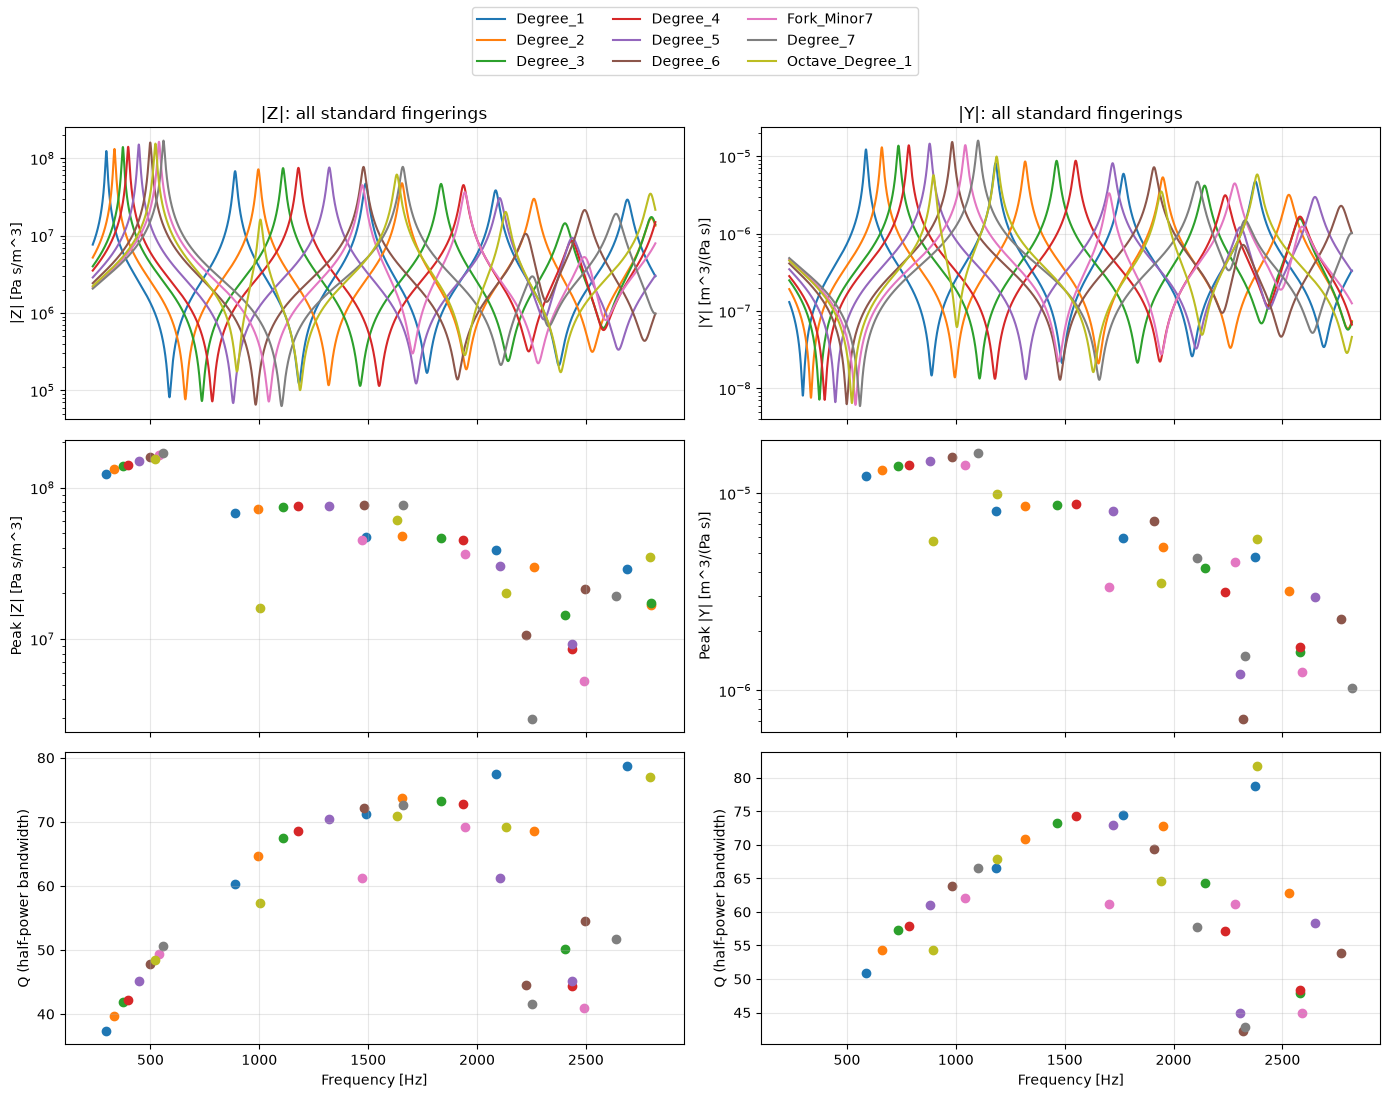

Fingering,Holes (L1-R3),Quantity,Mode,Peak (Hz),Peak amplitude,Unit,Lower -3 dB (Hz),Upper -3 dB (Hz),Bandwidth (Hz),Q,Status
Degree_1,x x x x x x,Z,1,297.34,1.239e+08,Pa s/m^3,293.36,301.33,7.97,37.31,OK
Degree_1,x x x x x x,Z,2,888.79,6.805e+07,Pa s/m^3,881.41,896.16,14.75,60.27,OK
Degree_1,x x x x x x,Z,3,1488.54,4.7e+07,Pa s/m^3,1478.05,1498.96,20.91,71.19,OK
Degree_1,x x x x x x,Z,4,2085.60,3.845e+07,Pa s/m^3,2072.06,2099.01,26.94,77.41,OK
Degree_1,x x x x x x,Z,5,2690.51,2.92e+07,Pa s/m^3,2673.28,2707.44,34.16,78.77,OK
Degree_2,x x x x x o,Z,1,334.67,1.319e+08,Pa s/m^3,330.45,338.88,8.43,39.70,OK
Degree_2,x x x x x o,Z,2,995.61,7.192e+07,Pa s/m^3,987.89,1003.31,15.41,64.60,OK
Degree_2,x x x x x o,Z,3,1655.31,4.755e+07,Pa s/m^3,1644.04,1666.48,22.44,73.77,OK
Degree_2,x x x x x o,Z,4,2261.42,2.991e+07,Pa s/m^3,2244.79,2277.78,32.99,68.55,OK
Degree_2,x x x x x o,Z,5,2801.02,1.683e+07,Pa s/m^3,nicht bestimmbar,nicht bestimmbar,nicht bestimmbar,nicht bestimmbar,Half-power crossings unavailable in peak basin


Fingering,Holes (L1-R3),Quantity,Mode,Peak (Hz),Peak amplitude,Unit,Lower -3 dB (Hz),Upper -3 dB (Hz),Bandwidth (Hz),Q,Status
Degree_1,x x x x x x,Y,1,587.30,1.228e-05,m^3/(Pa s),581.53,593.08,11.55,50.83,OK
Degree_1,x x x x x x,Y,2,1182.54,8.163e-06,m^3/(Pa s),1173.68,1191.43,17.75,66.62,OK
Degree_1,x x x x x x,Y,3,1770.22,5.95e-06,m^3/(Pa s),1758.38,1782.16,23.78,74.44,OK
Degree_1,x x x x x x,Y,4,2375.89,4.748e-06,m^3/(Pa s),2360.89,2391.07,30.18,78.73,OK
Degree_2,x x x x x o,Y,1,660.13,1.307e-05,m^3/(Pa s),654.07,666.20,12.14,54.39,OK
Degree_2,x x x x x o,Y,2,1318.39,8.579e-06,m^3/(Pa s),1309.11,1327.70,18.59,70.92,OK
Degree_2,x x x x x o,Y,3,1950.75,5.355e-06,m^3/(Pa s),1937.40,1964.21,26.81,72.76,OK
Degree_2,x x x x x o,Y,4,2529.61,3.184e-06,m^3/(Pa s),2509.59,2549.89,40.30,62.77,OK
Degree_3,x x x x o o,Y,1,736.36,1.374e-05,m^3/(Pa s),729.94,742.80,12.86,57.26,OK
Degree_3,x x x x o o,Y,2,1463.03,8.76e-06,m^3/(Pa s),1453.06,1473.05,19.99,73.20,OK


In [10]:
from tin_whistle_openwind.resonances import (
    compare_fingering_resonances, plot_resonance_comparison,
)

SPECTRUM_STEP_HZ = 0.25
spectrum_min_hz = 0.4 * key_config.root_freq_12tet_hz
spectrum_max_hz = 2.4 * max(targets_hz.values())
spectrum_frequencies_hz = np.arange(
    spectrum_min_hz, spectrum_max_hz, SPECTRUM_STEP_HZ,
)
resonance_comparison = compare_fingering_resonances(
    design.bore, design.holes,
    pipeline.geometry_factory.load_mouthpiece('MouthpieceDN16V2'),
    spectrum_frequencies_hz, temperature=pipeline.geometry_factory.temperature,
)
resonance_figure = plot_resonance_comparison(resonance_comparison)
plt.show()

resonance_table = pd.DataFrame(resonance_comparison.peak_rows)
for quantity in ('Z', 'Y'):
    table = resonance_table[resonance_table['Quantity'] == quantity]
    display(table.style.hide(axis='index').set_caption(
        f'{quantity}: Peaks und Halb-Leistungs-Q aller Griffe'
    ).format({
        'Peak (Hz)': '{:.2f}', 'Peak amplitude': '{:.4g}',
        'Lower -3 dB (Hz)': '{:.2f}', 'Upper -3 dB (Hz)': '{:.2f}',
        'Bandwidth (Hz)': '{:.2f}', 'Q': '{:.2f}',
    }, na_rep='nicht bestimmbar'))

## 6. CAD-Export

Die vollständige dreistufige Konstruktion und ein kompakter Bohrplan werden als JSON/CSV exportiert.

In [9]:
output_dir = Path('../data')
output_dir.mkdir(parents=True, exist_ok=True)
design_path = output_dir / f'whistle_design_{KEY_NAME}_{TEMPERAMENT_NAME}.json'
design_path.write_text(json.dumps(design.to_dict(), indent=2), encoding='utf-8')
drill_path = output_dir / f'drilling_chart_{KEY_NAME}.csv'
drill_export = pd.DataFrame(rows)[[
    'Hole', 'Position from pipe start (mm)', 'Spacing (mm)', 'Drill diameter (mm)',
]]
drill_export.columns = ['Hole', 'Position_mm', 'Spacing_mm', 'Drill_Diameter_mm']
drill_export.to_csv(drill_path, index=False, float_format='%.2f')
print(design_path.resolve())
print(drill_path.resolve())

C:\projects\p\openWind\data\whistle_design_Soprano_D_Irish_Folk_Hybrid.json
C:\projects\p\openWind\data\drilling_chart_Soprano_D.csv
